# Análise de vibração de hélices de drone (DronePropB) — 1ª entrega

Notebook único e linear: rode **de cima para baixo** (Ambiente de execução → Executar tudo). Só é preciso apontar `DATA_DIR` (célula 0) para a pasta com os `.mat` do DronePropB.

Escopo: **acelerômetro `AccData` (ACC)**, repetição **R1**, velocidades **SP1–SP3**, canais **C1–C3**.

| Requisito | Onde está |
|---|---|
| 3.1 Dados, metadados, validade e janelamento | Seção 3.1 |
| 3.2 Gráfico no tempo, 7 características, tabela, boxplots, interpretação | Seção 3.2 |
| 3.3 FFT, espectros, 5 medidas, tabela, boxplots, interpretação | Seção 3.3 |
| 3.3.6 Efeito da duração ($\Delta f = f_s/N$) | Seção 3.3.6 |
| 3.3.7 Efeito da amostragem (*aliasing*) | Seção 3.3.7 |
| 3.4 Comparação tempo × frequência e redundância | Seção 3.4 |
| 3.6 Investigação adicional | Seção 3.6 |

> **Sobre os textos de interpretação:** os números citados vêm da execução anterior do projeto com os mesmos 87 registros (ACC, R1). Depois de rodar, confira se batem com as tabelas geradas aqui e ajuste o que for preciso. Trechos que você precisa completar ou confirmar estão marcados com ✏️.

## 0. Configuração

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.signal import find_peaks, resample_poly
from sklearn.metrics import roc_auc_score
from IPython.display import display

# No Colab, com os dados no Google Drive:
# from google.colab import drive; drive.mount("/content/drive")
# DATA_DIR = Path("/content/drive/MyDrive/DronePropB")
DATA_DIR = Path("./dataset")          # pasta com os .mat do DronePropB

UNIDADE = "g"                         # unidade do AccData (ver nota na seção 3.1)
JANELA_S = 4.0                        # duração de cada janela [s]
SOBREPOSICAO = 0.5                    # 50 % de sobreposição entre janelas

# Par fixo usado em 3.2, 3.3 e 3.4: mesma velocidade (SP1), mesmo canal (C1), mesma sessão (R1)
PAR = {"saudável": "F0_SV0_SP1_C1_R1", "defeituoso": "F2_SV2_SP1_C1"}

# Bandas de frequência [Hz): juntas cobrem todo o eixo de 0 a Nyquist (DC excluído)
BANDAS = {"B1": (0, 50), "B2": (50, 300), "B3": (300, 5000)}

CORES = {"saudável": "tab:blue", "defeituoso": "tab:red"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200, "display.max_columns", 30)

## 3.1 Dados e janelamento

### 3.1.1 Seleção dos registros

Convenção dos nomes: `F{falha}_SV{severidade}_SP{velocidade}_C{canal}[_R{repetição}].mat`, com `F0` = hélice saudável e `F1–F3` = tipos de defeito (severidades `SV1–SV3`).

Critérios de seleção:

- **Sensor:** só o `AccData` (acelerômetro de 1 eixo, 10 kHz). O `IMUData` fica fora desta entrega.
- **Velocidades SP1–SP3 e canais C1–C3.** ✏️ SP0 e C4 ficam fora (recorte já adotado no projeto; justifique no relatório).
- **Repetição R1:** os registros defeituosos só existem na sessão de set/2024 (R1). Os saudáveis R2 e R3 são de outra sessão (nov/2024), e misturá-los faria a comparação refletir a diferença de sessão, não a de hélice.
- **Sem o canal duplicado:** o arquivo saudável `C2` é uma cópia exata do `C1` (verificado abaixo), então fica de fora.

**Comparação entre condições:** saudável × defeituoso sempre na **mesma velocidade, canal e sessão**, para que a única diferença controlada seja o estado da hélice.

In [2]:
PADRAO = re.compile(r"F(\d+)_SV(\d+)_SP(\d+)_C(\d+)(?:_R(\d+))?$")

linhas = []
for p in sorted(DATA_DIR.glob("*.mat")):
    m = PADRAO.match(p.stem)
    if m:
        f, sv, sp, c, r = (int(g) if g else 1 for g in m.groups())   # sem _R -> repetição 1
        linhas.append(dict(record_id=p.stem, arquivo=p, fault=f, severity=sv,
                           speed=sp, channel=c, repetition=r))
assert linhas, f"Nenhum .mat encontrado em {DATA_DIR.resolve()} — ajuste DATA_DIR."
todos = pd.DataFrame(linhas)

sel = todos[todos.speed.between(1, 3) & todos.channel.between(1, 3)
            & (todos.repetition == 1)
            & ~((todos.fault == 0) & (todos.channel == 2))].reset_index(drop=True)
sel["condicao"] = np.where(sel.fault == 0, "saudável", "defeituoso")

print(f"{len(todos)} arquivos no diretório -> {len(sel)} registros selecionados (esperado: 87)")
display(sel.groupby(["condicao", "speed"]).size().unstack().rename(columns=lambda s: f"SP{s}"))

111 arquivos no diretório -> 87 registros selecionados (esperado: 87)


speed,SP1,SP2,SP3
condicao,,,
defeituoso,27,27,27
saudável,2,2,2


In [3]:
def ler_acc(caminho):
    # Lê o acelerômetro de um .mat: (sinal, tempo, fs, data de aquisição).
    s = sio.loadmat(caminho, squeeze_me=True, struct_as_record=False)["AccData"]
    x = np.asarray(s.Vib_Data, dtype=np.float64).ravel()
    t = np.asarray(s.t, dtype=np.float64).ravel()
    return x, t, float(s.samplingRate), str(getattr(s, "DATE", ""))


# Campos disponíveis no AccData (útil para procurar alguma informação de unidade)
s0 = sio.loadmat(sel.arquivo[0], squeeze_me=True, struct_as_record=False)["AccData"]
print("Campos do AccData:", s0._fieldnames)

# Confirma que o C2 saudável é cópia do C1
a, b = DATA_DIR / "F0_SV0_SP1_C1_R1.mat", DATA_DIR / "F0_SV0_SP1_C2_R1.mat"
if a.exists() and b.exists():
    print("F0 ... C2 idêntico ao C1?", np.array_equal(ler_acc(a)[0], ler_acc(b)[0]))

Campos do AccData: ['DATE', 'samplingRate', 't', 'Vib_Data']
F0 ... C2 idêntico ao C1? True


**Unidade.** A página do DronePropB descreve um acelerômetro piezoelétrico de alta sensibilidade, mas **não informa a unidade** do `AccData`, e os campos do `.mat` listados acima também não. Adotamos **g** (ordem de grandeza compatível: ±0,2 em SP1) e declaramos isso no relatório como **hipótese**. ✏️ Se encontrar a unidade no artigo do dataset, troque `UNIDADE` na célula 0 e cite a fonte.

### 3.1.2 Verificação de validade e janelamento

Para cada registro verificamos: valores inválidos (`NaN`/`Inf`), $f_s$, nº de amostras e duração, vetor de tempo crescente, **lacunas** no tempo (intervalo entre amostras > 1,5/$f_s$) e fração de amostras no valor máximo/mínimo (indício de saturação).

Tratamentos aplicados (só os necessários): nenhum filtro, nenhuma remoção de média e nenhum recorte. Registros com valores inválidos ou tempo não crescente seriam descartados, e **janelas que atravessam uma lacuna** são descartadas, porque nelas o espaçamento entre amostras deixa de ser $1/f_s$ e a FFT perde validade.

Janelamento: janelas de **4 s** com **50 %** de sobreposição. Cada janela guarda o `record_id` de origem.

In [4]:
janelas, indice, meta = [], [], []
for r in sel.itertuples():
    x, t, fs, data = ler_acc(r.arquivo)
    dt = np.diff(t)
    lacunas = np.where(dt > 1.5 / fs)[0] + 1               # 1ª amostra depois de cada lacuna
    q = dict(record_id=r.record_id, condicao=r.condicao, fault=r.fault, severity=r.severity,
             speed=r.speed, channel=r.channel, sensor="ACC", eixo="único", unidade=UNIDADE,
             data=data, fs_hz=fs, n_amostras=x.size, duracao_s=x.size / fs,
             n_nan_inf=int((~np.isfinite(x)).sum()), t_crescente=bool((dt > 0).all()),
             n_lacunas=len(lacunas),
             frac_no_extremo=float(np.mean((x == x.max()) | (x == x.min()))))

    N = int(round(JANELA_S * fs))
    passo = int(N * (1 - SOBREPOSICAO))
    inicios = np.arange(0, x.size - N + 1, passo)
    validas = [i0 for i0 in inicios if not np.any((lacunas > i0) & (lacunas < i0 + N))]
    if q["n_nan_inf"] or not q["t_crescente"]:
        validas = []                                        # registro reprovado
    q["janelas"], q["janelas_descartadas"] = len(validas), len(inicios) - len(validas)
    meta.append(q)
    for k, i0 in enumerate(validas):
        janelas.append(x[i0:i0 + N].astype(np.float32))
        indice.append(dict(record_id=r.record_id, janela=k, t_inicio_s=i0 / fs))

meta = pd.DataFrame(meta)
assert meta.fs_hz.nunique() == 1, "Registros com fs diferentes"
FS = meta.fs_hz.iloc[0]
W = np.stack(janelas)                                       # (n_janelas, amostras)
jan = pd.DataFrame(indice).merge(
    meta[["record_id", "condicao", "fault", "severity", "speed", "channel"]], on="record_id")

print(f"Valores inválidos: {meta.n_nan_inf.sum()} | tempo não crescente: {(~meta.t_crescente).sum()} "
      f"| registros com lacunas: {(meta.n_lacunas > 0).sum()} "
      f"| janelas descartadas por lacuna: {meta.janelas_descartadas.sum()}")
print(f"Maior fração de amostras no máx./mín.: {meta.frac_no_extremo.max():.1e}")
print(f"Janelas: {len(W)} de {JANELA_S:.0f} s = {W.shape[1]} amostras @ {FS:.0f} Hz, "
      f"sobreposição {SOBREPOSICAO:.0%}")

Valores inválidos: 0 | tempo não crescente: 0 | registros com lacunas: 0 | janelas descartadas por lacuna: 0
Maior fração de amostras no máx./mín.: 1.5e-05
Janelas: 1923 de 4 s = 40000 amostras @ 10000 Hz, sobreposição 50%


**Tabela de metadados** (resumo por condição e velocidade, para o relatório) e tabela completa por registro:

In [5]:
resumo_31 = meta.groupby(["condicao", "speed"]).agg(
    registros=("record_id", "size"), fs_hz=("fs_hz", "first"),
    duracao_min_s=("duracao_s", "min"), duracao_max_s=("duracao_s", "max"),
    amostras_max=("n_amostras", "max"), janelas=("janelas", "sum"))
display(resumo_31)
display(meta.drop(columns=["frac_no_extremo"]))

registros    fs_hz  duracao_min_s  duracao_max_s  amostras_max  janelas
condicao   speed                                                                         
defeituoso 1             27  10000.0           20.0           60.0        600000      603
           2             27  10000.0           20.0           60.0        600000      603
           3             27  10000.0           20.0           60.0        600000      603
saudável   1              2  10000.0           20.0           60.0        600000       38
           2              2  10000.0           20.0           60.0        600000       38
           3              2  10000.0           20.0           60.0        600000       38

,record_id,condicao,fault,severity,speed,channel,sensor,eixo,unidade,data,fs_hz,n_amostras,duracao_s,n_nan_inf,t_crescente,n_lacunas,janelas,janelas_descartadas
0,F0_SV0_SP1_C1_R1,saudável,0,0,1,1,ACC,único,g,25-Sep-2024,10000.0,600000,60.0,0,True,0,29,0
1,F0_SV0_SP1_C3_R1,saudável,0,0,1,3,ACC,único,g,29-Sep-2024,10000.0,200000,20.0,0,True,0,9,0
2,F0_SV0_SP2_C1_R1,saudável,0,0,2,1,ACC,único,g,25-Sep-2024,10000.0,600000,60.0,0,True,0,29,0
3,F0_SV0_SP2_C3_R1,saudável,0,0,2,3,ACC,único,g,29-Sep-2024,10000.0,200000,20.0,0,True,0,9,0
4,F0_SV0_SP3_C1_R1,saudável,0,0,3,1,ACC,único,g,25-Sep-2024,10000.0,600000,60.0,0,True,0,29,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,F3_SV3_SP2_C2,defeituoso,3,3,2,2,ACC,único,g,25-Sep-2024,10000.0,600000,60.0,0,True,0,29,0
83,F3_SV3_SP2_C3,defeituoso,3,3,2,3,ACC,único,g,29-Sep-2024,10000.0,200000,20.0,0,True,0,9,0
84,F3_SV3_SP3_C1,defeituoso,3,3,3,1,ACC,único,g,25-Sep-2024,10000.0,600000,60.0,0,True,0,29,0
85,F3_SV3_SP3_C2,defeituoso,3,3,3,2,ACC,único,g,25-Sep-2024,10000.0,600000,60.0,0,True,0,29,0


## 3.2 Domínio do tempo

### 3.2.1 Sinal no tempo: saudável × defeituoso

Par fixo (célula 0): `F0_SV0_SP1_C1_R1` × `F2_SV2_SP1_C1`, ambos em SP1, canal C1, sessão R1. Mostramos a **janela central** de cada registro (4 s) e um zoom nos primeiros 50 ms, com a mesma escala vertical nas duas condições. O sinal é mostrado **sem remover a média**.

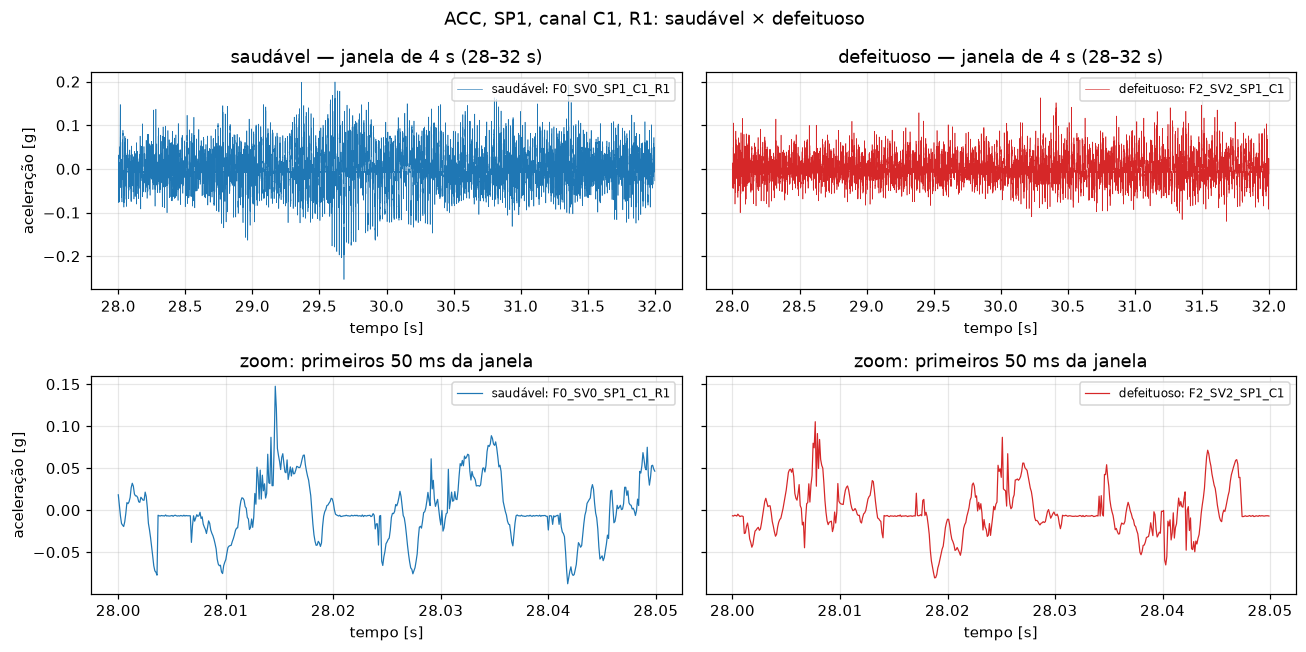

In [6]:
def janela_central(rid):
    pos = np.flatnonzero(jan.record_id == rid)
    return pos[len(pos) // 2]


fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharey="row")
for j, (cond, rid) in enumerate(PAR.items()):
    i = janela_central(rid)
    x = W[i]
    t = jan.t_inicio_s[i] + np.arange(x.size) / FS
    n = int(0.05 * FS)
    ax[0, j].plot(t, x, lw=0.4, color=CORES[cond], label=f"{cond}: {rid}")
    ax[1, j].plot(t[:n], x[:n], lw=0.8, color=CORES[cond], label=f"{cond}: {rid}")
    ax[0, j].set_title(f"{cond} — janela de {JANELA_S:.0f} s ({t[0]:.0f}–{t[-1]:.0f} s)")
    ax[1, j].set_title("zoom: primeiros 50 ms da janela")
    for a in ax[:, j]:
        a.set_xlabel("tempo [s]")
        a.legend(loc="upper right", fontsize=8)
for a in ax[:, 0]:
    a.set_ylabel(f"aceleração [{UNIDADE}]")
fig.suptitle("ACC, SP1, canal C1, R1: saudável × defeituoso")
fig.tight_layout()
plt.show()

### 3.2.2 Características no domínio do tempo

Para cada janela $x[n]$, $n = 0,\dots,N-1$:

| Característica | Definição | Unidade |
|---|---|---|
| Média | $\mu = \frac{1}{N}\sum x[n]$ | g |
| Potência média | $P = \frac{1}{N}\sum x[n]^2$ | g² |
| RMS | $\sqrt{P}$ | g |
| Desvio padrão | $\sigma = \sqrt{\frac{1}{N}\sum (x[n]-\mu)^2}$ | g |
| Pico absoluto | $\max_n \lvert x[n] \rvert$ | g |
| Pico a pico | $\max_n x[n] - \min_n x[n]$ | g |
| Fator de crista | pico absoluto / RMS | adimensional |

Identidade útil: $P = \text{RMS}^2 = \mu^2 + \sigma^2$.

In [7]:
FT = ["media", "rms", "potencia", "std", "pico_abs", "pico_pico", "crista"]


def features_tempo(B):
    B = B.astype(np.float64)
    pot = (B ** 2).mean(axis=1)
    pico = np.abs(B).max(axis=1)
    return pd.DataFrame(dict(media=B.mean(axis=1), rms=np.sqrt(pot), potencia=pot,
                             std=B.std(axis=1), pico_abs=pico,
                             pico_pico=B.max(axis=1) - B.min(axis=1),
                             crista=pico / np.sqrt(pot)))


def em_blocos(func, n=200):
    # Aplica func a blocos de n janelas (evita estourar a memória do Colab).
    return pd.concat([func(W[i:i + n]) for i in range(0, len(W), n)], ignore_index=True)


def resumo(df, cols):
    # Tabela 'média ± desvio padrão' das janelas por velocidade e condição.
    g = df.groupby(["speed", "condicao"])[cols]
    m, s = g.mean(), g.std()
    return m.apply(lambda c: c.map("{:.4g}".format)) + " ± " + s.apply(lambda c: c.map("{:.2g}".format))


ft = pd.concat([jan, em_blocos(features_tempo)], axis=1)
print("Tabela resumo (média ± desvio padrão das janelas):")
display(resumo(ft, FT))

Tabela resumo (média ± desvio padrão das janelas):


media               rms             potencia               std        pico_abs       pico_pico        crista
speed condicao                                                                                                                               
1     defeituoso   -0.001078 ± 0.00022  0.02633 ± 0.0083  0.0007629 ± 0.00053  0.02631 ± 0.0083  0.1585 ± 0.037  0.2788 ± 0.065   6.19 ± 0.82
      saudável    -0.0009624 ± 0.00024   0.03721 ± 0.013   0.001552 ± 0.00078    0.0372 ± 0.013   0.1953 ± 0.06   0.3666 ± 0.11  5.509 ± 0.95
2     defeituoso   -0.001182 ± 0.00039    0.09094 ± 0.02    0.008676 ± 0.0033    0.09093 ± 0.02    0.464 ± 0.12   0.8632 ± 0.21  5.081 ± 0.53
      saudável     -0.001139 ± 0.00019   0.08106 ± 0.024    0.007131 ± 0.0033   0.08105 ± 0.024   0.4111 ± 0.13   0.7694 ± 0.24  5.074 ± 0.53
3     defeituoso   -0.001622 ± 0.00089     0.263 ± 0.098      0.07874 ± 0.061     0.263 ± 0.098    1.075 ± 0.37     2.048 ± 0.7  4.142 ± 0.57
      saudável     -0.001657 ± 0.00058    0.2559 ± 0.072      0.07055 ± 0.032    0.2559 ± 0.072   0.9337 ± 0.29    1.789 ± 0.57  3.598 ± 0.31

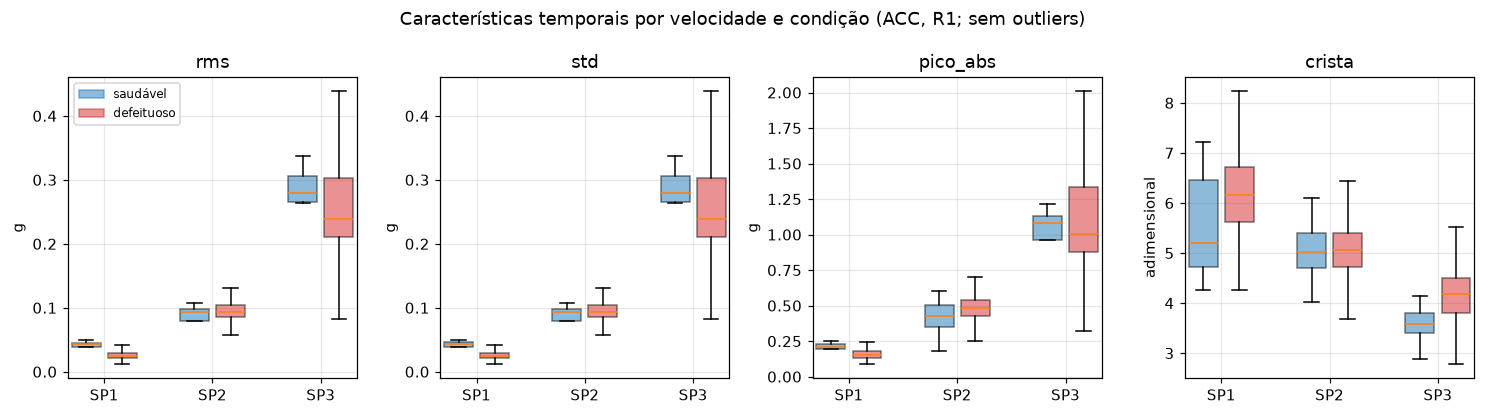

In [8]:
UNID = {"media": UNIDADE, "rms": UNIDADE, "potencia": f"{UNIDADE}²", "std": UNIDADE,
        "pico_abs": UNIDADE, "pico_pico": UNIDADE, "crista": "adimensional"}


def boxplots(df, cols, titulo, log=()):
    # Um painel por característica; caixas agrupadas por velocidade e condição.
    sps = sorted(df.speed.unique())
    fig, axs = plt.subplots(1, len(cols), figsize=(3.4 * len(cols), 3.8))
    for a, c in zip(np.atleast_1d(axs), cols):
        dados, pos, cores = [], [], []
        for i, sp in enumerate(sps):
            for j, cond in enumerate(CORES):
                dados.append(df.loc[(df.speed == sp) & (df.condicao == cond), c])
                pos.append(3 * i + j)
                cores.append(CORES[cond])
        bp = a.boxplot(dados, positions=pos, widths=0.8, patch_artist=True, showfliers=False)
        for caixa, cor in zip(bp["boxes"], cores):
            caixa.set_facecolor(cor)
            caixa.set_alpha(0.5)
        a.set_xticks([3 * i + 0.5 for i in range(len(sps))])
        a.set_xticklabels([f"SP{sp}" for sp in sps])
        a.set_title(c)
        a.set_ylabel(UNID.get(c, ""))
        if c in log:
            a.set_yscale("log")
    np.atleast_1d(axs)[0].legend([plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.5) for c in CORES.values()],
                                 list(CORES), fontsize=8)
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()


boxplots(ft, ["rms", "std", "pico_abs", "crista"],
         "Características temporais por velocidade e condição (ACC, R1; sem outliers)")

In [9]:
# Relação RMS × potência e efeito da componente média (DC)
erro = np.max(np.abs(ft.rms ** 2 - (ft.media ** 2 + ft["std"] ** 2)))
print(f"max |RMS² − (μ² + σ²)| = {erro:.1e}   (identidade verificada)")
print(f"max |potência − RMS²|  = {np.max(np.abs(ft.potencia - ft.rms ** 2)):.1e}")

frac_dc = (ft.media ** 2 / ft.potencia).rename("μ²/P")
print("\nFração da potência na componente média (μ²/P), por velocidade e condição:")
display(frac_dc.groupby([ft.speed, ft.condicao]).agg(["median", "max"]))

max |RMS² − (μ² + σ²)| = 1.7e-16   (identidade verificada)
max |potência − RMS²|  = 5.6e-17

Fração da potência na componente média (μ²/P), por velocidade e condição:


median       max
speed condicao                      
1     defeituoso  0.001952  0.008770
      saudável    0.000710  0.004758
2     defeituoso  0.000170  0.000959
      saudável    0.000174  0.000657
3     defeituoso  0.000040  0.000320
      saudável    0.000044  0.000125

### 3.2.3 Interpretação

✏️ *Confira os números com as tabelas acima.*

- **Diferenças entre condições.** Em SP1 o saudável tem **mais** energia que o defeituoso (RMS ≈ 0,037 g × 0,026 g; pico absoluto ≈ 0,20 g × 0,16 g). Em SP2 e SP3 a relação **se inverte** e a diferença fica pequena perto da dispersão (RMS ≈ 0,081 × 0,091 g em SP2; 0,26 × 0,26 g em SP3). Ou seja, a energia do sinal sozinha não indica a condição de forma consistente.
- **Fator de crista** é maior no defeituoso nas três velocidades (≈ 6,2 × 5,5 em SP1; 4,1 × 3,6 em SP3; praticamente igual em SP2): o defeituoso tem picos relativamente mais altos para a mesma energia, isto é, é mais impulsivo.
- **Efeito da velocidade.** Todas as medidas de amplitude crescem muito de SP1 para SP3 (RMS ~7×), bem mais do que a diferença entre condições. Por isso as comparações são sempre feitas **dentro da mesma velocidade**.
- **Semelhanças e redundâncias.** RMS, desvio padrão e potência carregam a mesma informação (veja o próximo item). Pico absoluto e pico a pico acompanham o desvio padrão de perto, já que o sinal é aproximadamente simétrico (pico a pico ≈ 2 × pico absoluto).
- **RMS × potência média.** Por definição, $P = \text{RMS}^2$: são a mesma medida em escalas diferentes (g² × g). A identidade $\text{RMS}^2 = \mu^2 + \sigma^2$ foi verificada numericamente (erro ~$10^{-13}$).
- **Componente média (DC).** A média é ≈ −0,001 g em todas as condições, e $\mu^2/P$ fica abaixo de 0,1 % da potência. Logo $\text{RMS} \approx \sigma$, e a média não discrimina as hélices (é um pequeno *offset* do sensor). No gráfico temporal, o zoom mostra pequenos patamares constantes **nas duas condições**, então eles não diferenciam as classes.

## 3.3 Domínio da frequência (FFT)

### 3.3.1 FFT e normalização

Para cada janela de $N = 40\,000$ amostras ($f_s = 10$ kHz, 4 s) calculamos a FFT unilateral `np.fft.rfft`, com eixo de frequências $f_k = k\,f_s/N$, $k = 0,\dots,N/2$ (resolução $\Delta f = f_s/N = 0{,}25$ Hz, até Nyquist = 5 kHz). Janela retangular, sem remover a média.

Normalização adotada:

- **Amplitude** (pico da senoide equivalente): $A[k] = 2\,|X[k]|/N$ para $0 < k < N/2$, e $A[0] = |X[0]|/N$ (DC, sem o fator 2). Assim, uma senoide de amplitude 0,02 g aparece como um pico de 0,02 g.
- **Potência por bin:** $P[k] = 2\,|X[k]|^2/N^2$ (DC e Nyquist sem o fator 2). Pelo **teorema de Parseval**, $\sum_k P[k] = \frac{1}{N}\sum_n x[n]^2$, ou seja, a soma dá exatamente a potência média da 3.2. Somar $P[k]$ dentro de uma banda dá a potência média do sinal naquela banda, em g².

### 3.3.2 Medidas espectrais (DC excluído de todas)

| Medida | Definição | Unidade |
|---|---|---|
| Frequência dominante | $f_k$ com maior $A[k]$, $k \ge 1$ | Hz |
| Magnitude do pico dominante | $A[k]$ nesse bin | g |
| Potência nas bandas B1, B2, B3 | $\sum_{k \in \text{banda}} P[k]$ | g² |
| Centroide espectral | $\sum f_k A[k] / \sum A[k]$ | Hz |
| Entropia espectral | $-\sum p_k \log_2 p_k / \log_2 K$, com $p_k = A[k]/\sum A$ | adimensional (0 a 1) |

**Bandas.** Os espectros (abaixo e na 3.6) mostram uma frequência fundamental de ~56 Hz em SP1, que sobe para ~98 Hz em SP2 e ~134 Hz em SP3, seguida de harmônicos.

- **B1 = 0–50 Hz:** abaixo da fundamental na menor velocidade; movimentos lentos e componentes de baixa frequência.
- **B2 = 50–300 Hz:** contém a fundamental e os primeiros harmônicos nas três velocidades.
- **B3 = 300–5000 Hz:** harmônicos de ordem alta, ressonâncias e o espectro de banda larga até Nyquist.

As três bandas são contíguas e cobrem todo o eixo sem o DC. Por Parseval, então, $P_{B1} + P_{B2} + P_{B3} = \sigma^2$: as bandas **repartem a variância** do sinal (verificado abaixo).

In [10]:
def fft_janelas(B, fs):
    # FFT unilateral de uma janela (1D) ou de várias (2D, uma por linha).
    # Retorna f [Hz], amplitude A [g] e potência por bin P [g²] (P.sum() = média de x²).
    B = np.asarray(B, dtype=np.float64)
    N = B.shape[-1]
    X = np.fft.rfft(B, axis=-1)
    f = np.fft.rfftfreq(N, d=1 / fs)
    A = np.abs(X) / N
    P = np.abs(X) ** 2 / N ** 2
    A[..., 1:(N + 1) // 2] *= 2          # bins com par conjugado (todos menos DC e Nyquist)
    P[..., 1:(N + 1) // 2] *= 2
    return f, A, P


def features_freq(B):
    f, A, P = fft_janelas(B, FS)
    f, A, P = f[1:], A[:, 1:], P[:, 1:]                      # sem DC
    i = A.argmax(axis=1)
    out = dict(freq_dominante=f[i], mag_dominante=A[np.arange(len(i)), i])
    for nome, (lo, hi) in BANDAS.items():
        m = (f >= lo) & ((f < hi) | (hi >= f[-1]))           # última banda inclui Nyquist
        out[f"pot_{nome}"] = P[:, m].sum(axis=1)
    p = A / A.sum(axis=1, keepdims=True)
    out["centroide"] = (p * f).sum(axis=1)
    out["entropia"] = -(p * np.log2(p + 1e-30)).sum(axis=1) / np.log2(f.size)
    return pd.DataFrame(out)


def top_picos(f, A, k=5, fmax=1000):
    # Os k picos mais proeminentes de A entre 1 Hz e fmax: lista de (freq, amplitude).
    m = (f > 1) & (f <= fmax)
    idx, prop = find_peaks(A[m], prominence=0.05 * A[m].max())
    ordem = np.argsort(prop["prominences"])[::-1][:k]
    return [(f[m][idx[o]], A[m][idx[o]]) for o in ordem]


FF = ["freq_dominante", "mag_dominante", "pot_B1", "pot_B2", "pot_B3", "centroide", "entropia"]
ff = pd.concat([jan, em_blocos(features_freq)], axis=1)

# Parseval: B1 + B2 + B3 (sem DC) = variância da janela
soma_bandas = ff[["pot_B1", "pot_B2", "pot_B3"]].sum(axis=1)
print(f"Parseval: max |ΣP_bandas − σ²| / σ² = {np.max(np.abs(soma_bandas - ft['std'] ** 2) / ft['std'] ** 2):.1e}")

Parseval: max |ΣP_bandas − σ²| / σ² = 1.6e-14


### 3.3.3 Espectros de magnitude: saudável × defeituoso

Mesmos registros da 3.2. Cada curva é a **média dos espectros de amplitude de todas as janelas do registro** (reduz a variância do espectro de uma janela só). Escala linear, mesmos eixos nas duas condições, com os 3 picos mais proeminentes anotados.

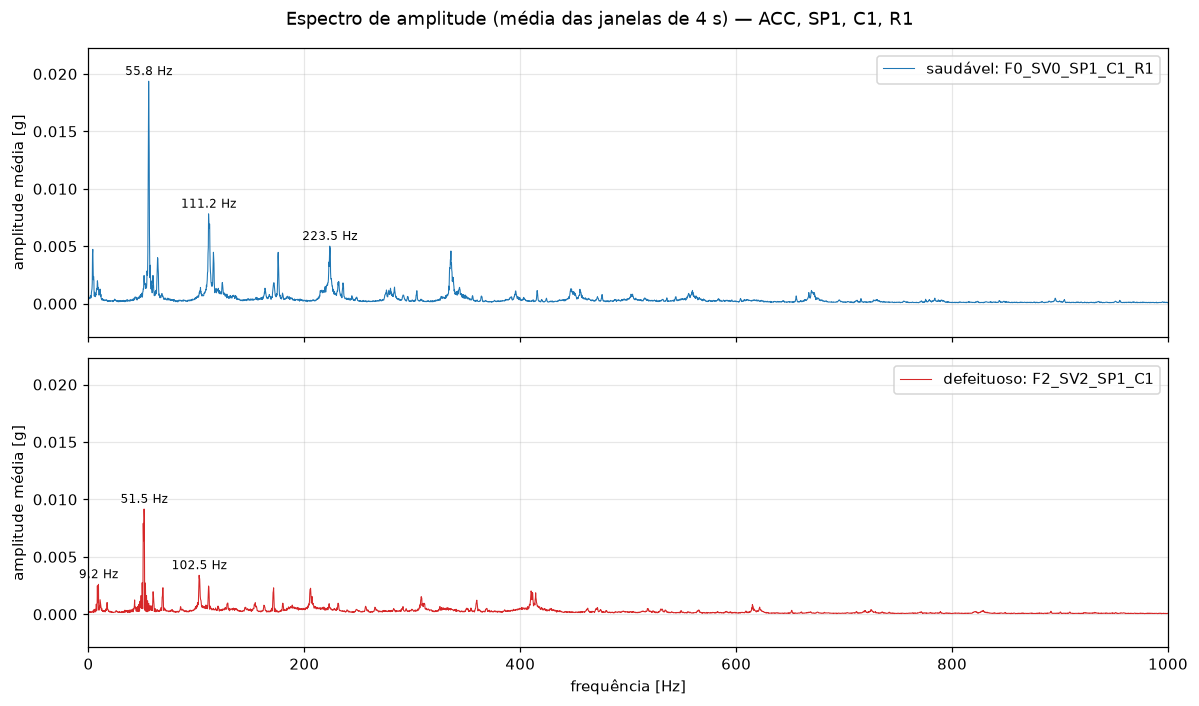

Picos mais proeminentes (até 1 kHz):


freq_hz           amplitude          
condicao defeituoso saudável defeituoso  saudável
ordem                                            
1             51.50    55.75   0.009162  0.019364
2            102.50   111.25   0.003398  0.007822
3              9.25   223.50   0.002612  0.005012
4             52.75   335.75   0.002726  0.004590
5             49.75     4.00   0.002749  0.004732

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, sharey=True)
tabela_picos = []
for a, (cond, rid) in zip(ax, PAR.items()):
    f, A, _ = fft_janelas(W[(jan.record_id == rid).to_numpy()], FS)
    Am = A.mean(axis=0)
    a.plot(f[1:], Am[1:], lw=0.7, color=CORES[cond], label=f"{cond}: {rid}")
    for fp, ap in top_picos(f, Am, k=3):
        a.annotate(f"{fp:.1f} Hz", (fp, ap), xytext=(0, 4), textcoords="offset points",
                   ha="center", fontsize=8)
    for n, (fp, ap) in enumerate(top_picos(f, Am, k=5), 1):
        tabela_picos.append(dict(condicao=cond, record_id=rid, ordem=n, freq_hz=round(fp, 2),
                                 amplitude=ap))
    a.set_ylabel(f"amplitude média [{UNIDADE}]")
    a.legend(loc="upper right")
    a.margins(y=0.15)                                   # espaço para as anotações
ax[-1].set_xlim(0, 1000)
ax[-1].set_xlabel("frequência [Hz]")
fig.suptitle("Espectro de amplitude (média das janelas de 4 s) — ACC, SP1, C1, R1")
fig.tight_layout()
plt.show()

print("Picos mais proeminentes (até 1 kHz):")
display(pd.DataFrame(tabela_picos).pivot(index="ordem", columns="condicao",
                                         values=["freq_hz", "amplitude"]))

### 3.3.4 Tabela resumo e comparação das características espectrais

Tabela resumo (média ± desvio padrão das janelas):


freq_dominante     mag_dominante               pot_B1               pot_B2               pot_B3       centroide         entropia
speed condicao                                                                                                                                     
1     defeituoso  122.5 ± 1.4e+02  0.01178 ± 0.0068  3.861e-05 ± 5.4e-05  0.0004797 ± 0.00041  0.0002434 ± 0.00012  1655 ± 1.2e+02  0.9446 ± 0.0077
      saudável          57.59 ± 9  0.02059 ± 0.0083  5.929e-05 ± 3.1e-05   0.001154 ± 0.00061  0.0003373 ± 0.00015  1685 ± 1.7e+02   0.9406 ± 0.012
2     defeituoso  265.6 ± 1.5e+02   0.03483 ± 0.011  0.0002026 ± 0.00011    0.003064 ± 0.0013    0.005407 ± 0.0023       1489 ± 74  0.9255 ± 0.0039
      saudável    130.2 ± 1.1e+02   0.03199 ± 0.008   0.000258 ± 0.00012    0.002839 ± 0.0013     0.004033 ± 0.002       1492 ± 87  0.9288 ± 0.0049
3     defeituoso  221.1 ± 1.2e+02    0.1407 ± 0.075    0.001871 ± 0.0016       0.0361 ± 0.038      0.04076 ± 0.031       1543 ± 90   0.918 ± 0.0063
      saudável        135.1 ± 2.9    0.1718 ± 0.046     0.00272 ± 0.0011       0.0489 ± 0.021       0.01893 ± 0.01  1622 ± 1.1e+02   0.9241 ± 0.006

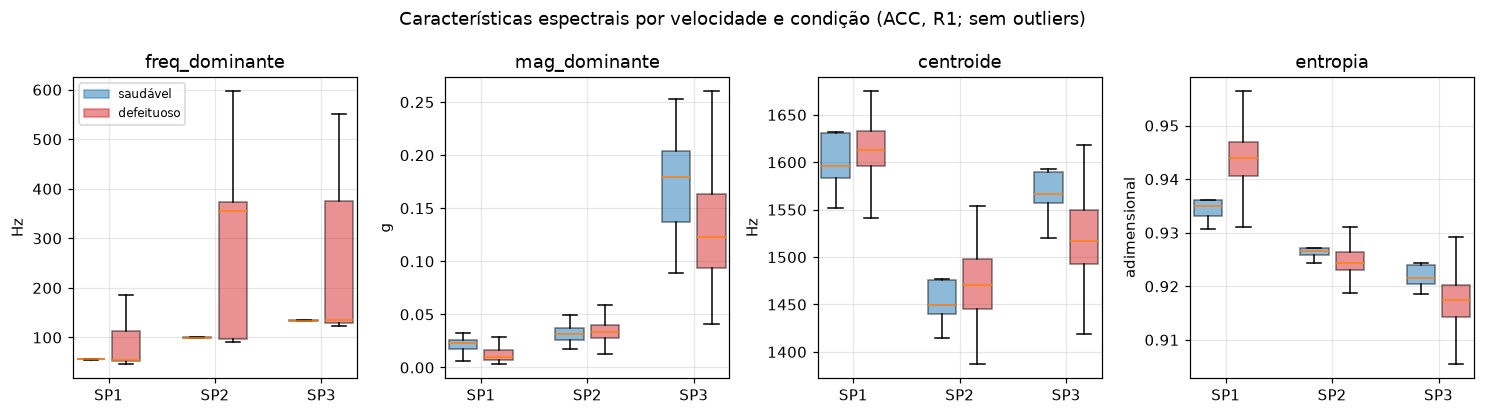

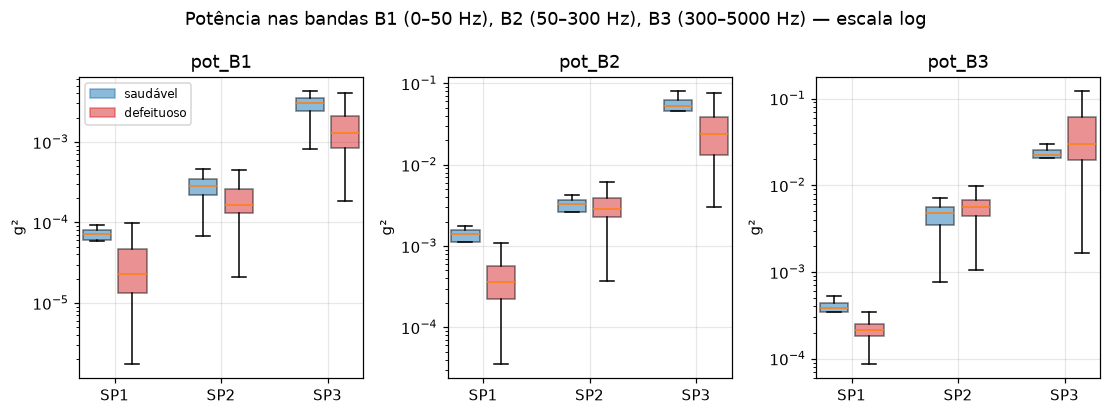

In [12]:
UNID.update(freq_dominante="Hz", mag_dominante=UNIDADE, pot_B1=f"{UNIDADE}²",
            pot_B2=f"{UNIDADE}²", pot_B3=f"{UNIDADE}²", centroide="Hz", entropia="adimensional")

print("Tabela resumo (média ± desvio padrão das janelas):")
display(resumo(ff, FF))

boxplots(ff, ["freq_dominante", "mag_dominante", "centroide", "entropia"],
         "Características espectrais por velocidade e condição (ACC, R1; sem outliers)")
boxplots(ff, ["pot_B1", "pot_B2", "pot_B3"],
         "Potência nas bandas B1 (0–50 Hz), B2 (50–300 Hz), B3 (300–5000 Hz) — escala log",
         log=("pot_B1", "pot_B2", "pot_B3"))

### 3.3.5 Interpretação

✏️ *Confira os números com as tabelas acima.*

- **Picos relevantes.** O saudável em SP1 tem um pico estreito e dominante em ~56 Hz e harmônicos em ~111, ~224 e ~335 Hz, uma série de múltiplos de uma mesma fundamental. No defeituoso, os picos nessas frequências são bem menores, e a energia aparece espalhada em picos mais largos e vizinhos (~53, ~60, ~106 Hz).
- **Frequência e magnitude dominantes.** No saudável em SP1 a frequência dominante é estável (≈ 58 ± 9 Hz entre janelas). No defeituoso ela salta entre picos (≈ 122 ± 135 Hz), porque nenhum pico domina com folga. A magnitude do pico dominante é menor no defeituoso em SP1 (≈ 0,012 × 0,021 g).
- **Forma do espectro.** O centroide (~1,5–1,7 kHz) e a entropia (~0,92–0,95) são altos nas duas condições, porque o espectro tem um piso largo até 5 kHz. As diferenças entre condições são pequenas em valor absoluto, mas aparecem nas três velocidades (ver 3.4).
- **Bandas.** ✏️ Descreva em qual banda a diferença entre condições é maior em cada velocidade (boxplots acima). Lembre que $P_{B1}+P_{B2}+P_{B3} = \sigma^2$: se uma condição tem mais energia total, tende a ter mais em todas as bandas, então é a **distribuição** entre as bandas que acrescenta informação.
- **O que a frequência mostra além do tempo.** No tempo vimos apenas que o saudável em SP1 tem mais energia. O espectro mostra **onde** está essa energia: concentrada na fundamental e nos harmônicos no saudável, e mais distribuída no defeituoso. Não atribuímos causa física a isso sem medida de rotação; o mais plausível é que a fundamental esteja ligada à rotação da hélice, o que é coerente com o deslocamento observado na 3.6.

### 3.3.6 Efeito da duração do sinal

Mesma janela central do registro saudável do par, analisada inteira (4 s) e só no seu primeiro segundo (1 s). A resolução em frequência é $\Delta f = f_s/N$: com menos amostras, os bins ficam mais espaçados.

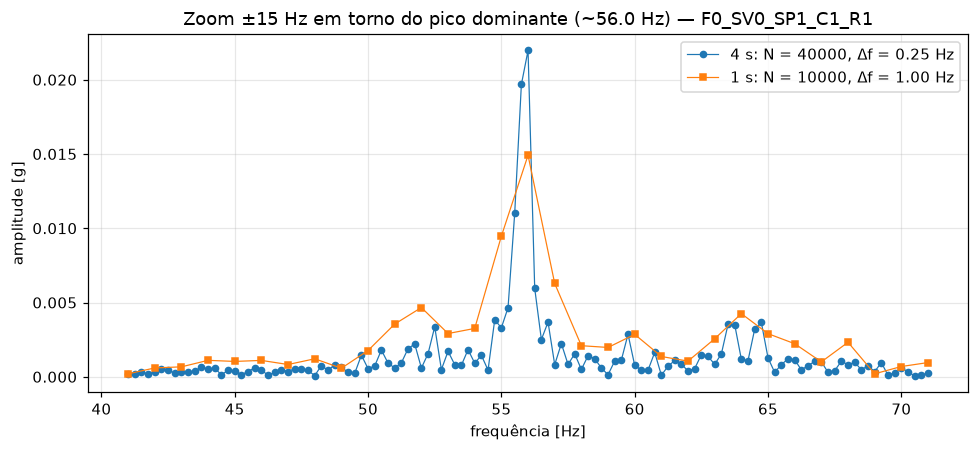

,duracao_s,N,delta_f_hz,pico_hz,amplitude_pico
0,4.0,40000,0.25,56.0,0.021970
1,1.0,10000,1.00,112.0,0.016605


In [13]:
x4 = W[janela_central(PAR["saudável"])].astype(np.float64)
x1 = x4[:int(1.0 * FS)]
f4, A4, _ = fft_janelas(x4, FS)
f_pico = f4[1:][A4[1:].argmax()]

fig, a = plt.subplots(figsize=(9, 4.2))
linhas = []
for x, estilo, cor in [(x4, "o-", "tab:blue"), (x1, "s-", "tab:orange")]:
    f, A, _ = fft_janelas(x, FS)
    m = np.abs(f - f_pico) <= 15
    N = x.size
    a.plot(f[m], A[m], estilo, ms=4, lw=0.8, color=cor,
           label=f"{N / FS:.0f} s: N = {N}, Δf = {FS / N:.2f} Hz")
    linhas.append(dict(duracao_s=N / FS, N=N, delta_f_hz=FS / N,
                       pico_hz=f[1:][A[1:].argmax()], amplitude_pico=A[1:].max()))
a.set_xlabel("frequência [Hz]")
a.set_ylabel(f"amplitude [{UNIDADE}]")
a.set_title(f"Zoom ±15 Hz em torno do pico dominante (~{f_pico:.1f} Hz) — {PAR['saudável']}")
a.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame(linhas))

**Interpretação.** Com 4 s ($N = 40\,000$), $\Delta f = 0{,}25$ Hz; com 1 s ($N = 10\,000$), $\Delta f = 1$ Hz, quatro vezes mais grosso. No zoom, cada marcador é um bin: com 1 s há 4× menos pontos para descrever o mesmo pico, que fica mais largo e com localização menos precisa (o pico real pode cair entre dois bins). Além disso, o trecho de 1 s tem menos ciclos para "promediar", então a altura do pico também muda. ✏️ Comente a diferença de frequência e amplitude do pico na tabela acima. **Compromisso:** janelas longas dão mais resolução em frequência, mas supõem que o sinal fica estável por mais tempo.

### 3.3.7 Efeito da taxa de amostragem (*aliasing*)

Reduzimos a taxa do mesmo trecho de 4 s por um fator **25**: de $f_s = 10$ kHz para **$f_s' = 400$ Hz** (novo Nyquist = 200 Hz), de duas formas:

- **sem filtro:** pegando 1 amostra a cada 25 (`x[::25]`);
- **com filtro anti-aliasing:** `scipy.signal.resample_poly`, que filtra passa-baixas antes de decimar.

O fator 25 foi escolhido porque os picos de 224 Hz e 335 Hz ficam acima do novo Nyquist e se dobram para frequências **entre** os harmônicos (≈ 176 Hz e ≈ 65 Hz), onde o pico falso fica fácil de ver.

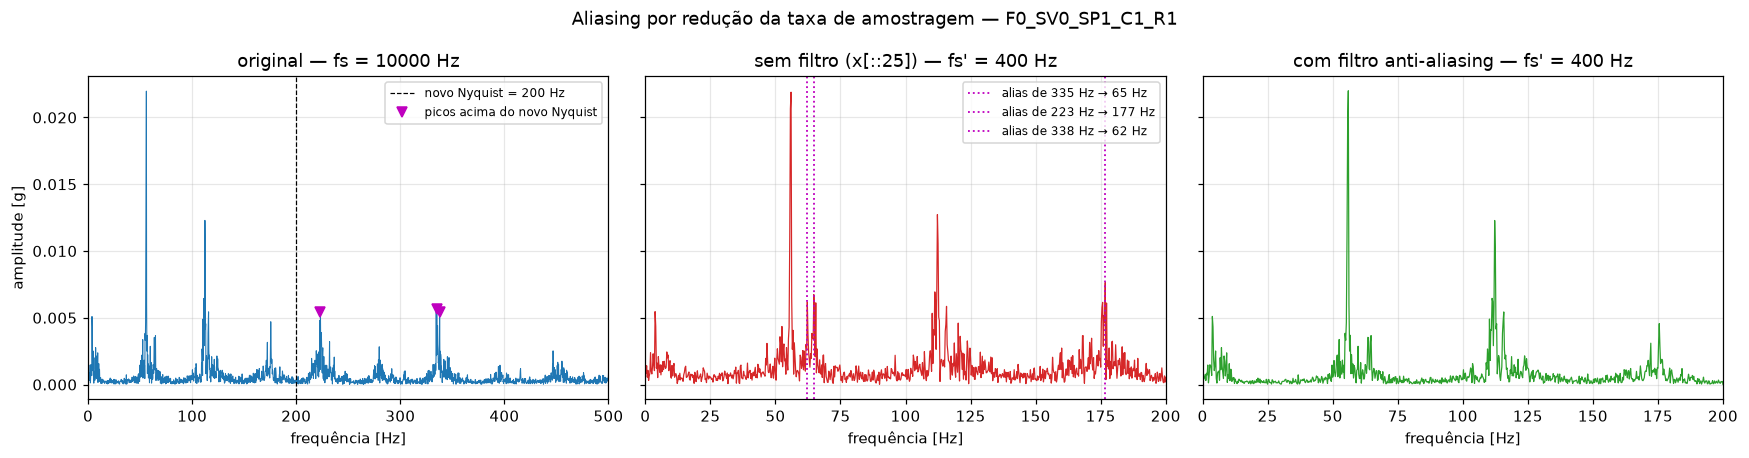

,pico_original_hz,alias_previsto_hz
0,335.0,65.0
1,223.2,176.8
2,337.8,62.2


In [14]:
FATOR = 25
fs2 = FS / FATOR
casos = {"sem filtro (x[::25])": (x4[::FATOR], "tab:red"),
         "com filtro anti-aliasing": (resample_poly(x4, 1, FATOR), "tab:green")}

# Alias previsto dos picos originais acima do novo Nyquist: f_a = |f − round(f/fs') · fs'|
acima = [fp for fp, _ in top_picos(f4, A4, k=8) if fp > fs2 / 2]
alias = pd.DataFrame({"pico_original_hz": acima,
                      "alias_previsto_hz": [abs(fp - round(fp / fs2) * fs2) for fp in acima]})

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
ax[0].plot(f4[1:], A4[1:], lw=0.7, color="tab:blue")
ax[0].axvline(fs2 / 2, color="k", ls="--", lw=0.8, label=f"novo Nyquist = {fs2 / 2:.0f} Hz")
ax[0].plot(alias.pico_original_hz, np.interp(alias.pico_original_hz, f4, A4), "v", color="m",
           label="picos acima do novo Nyquist")
ax[0].set_xlim(0, 500)
ax[0].set_title(f"original — fs = {FS:.0f} Hz")
for a, (nome, (sinal, cor)) in zip(ax[1:], casos.items()):
    f, A, _ = fft_janelas(sinal, fs2)
    a.plot(f[1:], A[1:], lw=0.8, color=cor)
    a.set_xlim(0, fs2 / 2)
    a.set_title(f"{nome} — fs' = {fs2:.0f} Hz")
for fp, fa in alias.itertuples(index=False):
    ax[1].axvline(fa, color="m", ls=":", lw=1.2, label=f"alias de {fp:.0f} Hz → {fa:.0f} Hz")
ax[0].set_ylabel(f"amplitude [{UNIDADE}]")
for a in ax:
    a.set_xlabel("frequência [Hz]")
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)
fig.suptitle(f"Aliasing por redução da taxa de amostragem — {PAR['saudável']}")
fig.tight_layout()
plt.show()
display(alias.round(1))

**Interpretação.** Pelo critério de Nyquist, uma taxa $f_s'$ só representa sem ambiguidade frequências até $f_s'/2$. Com $f_s' = 400$ Hz, tudo acima de 200 Hz que não for filtrado antes da decimação "dobra" para dentro de 0–200 Hz, em $f_a = |f - \text{round}(f/f_s')\,f_s'|$. Na decimação **sem filtro** aparecem picos nas frequências previstas (linhas pontilhadas) que não existem no sinal original nessa faixa, e o piso de ruído sobe, porque todo o conteúdo de 200 Hz a 5 kHz se soma dentro da faixa. Com o **filtro anti-aliasing**, esse conteúdo é removido antes de decimar: os picos falsos somem e os picos reais abaixo de 200 Hz (56 e 111 Hz) são preservados. ✏️ Confirme no gráfico os picos falsos nas frequências da tabela.

## 3.4 Comparação entre domínios

Mesmos registros e janelas nos dois domínios (87 registros, ACC, R1).

**Separabilidade.** Para cada característica e velocidade calculamos a **AUC** (área sob a curva ROC) entre saudável e defeituoso. Usamos a forma simétrica, $\max(\text{AUC}, 1-\text{AUC})$: 0,5 = nenhuma separação, 1 = separação perfeita. A coluna `sentido` indica se a mediana do defeituoso é maior (+) ou menor (−) que a do saudável em SP1, SP2 e SP3. AUC é só indicativa aqui: janelas do mesmo registro não são independentes.

In [15]:
df = pd.concat([ft, ff[FF]], axis=1)                     # mesmas linhas (janelas) nos dois domínios
dominio = {**{c: "Tempo" for c in FT}, **{c: "Frequência" for c in FF}}

def auc_simetrica(y, x):
    auc = roc_auc_score(y, x)
    return max(auc, 1 - auc)


tab = pd.DataFrame({f"SP{sp}": {c: auc_simetrica(g.condicao == "defeituoso", g[c]) for c in FT + FF}
                    for sp, g in df.groupby("speed")})
tab.insert(0, "domínio", tab.index.map(dominio))
tab["média"] = tab[["SP1", "SP2", "SP3"]].mean(axis=1)
med = df.groupby(["speed", "condicao"])[FT + FF].median()
tab["sentido"] = ["".join("+" if med.loc[(sp, "defeituoso"), c] > med.loc[(sp, "saudável"), c] else "−"
                          for sp in (1, 2, 3)) for c in tab.index]
display(tab.round(2).sort_values(["domínio", "média"], ascending=[False, False]))

,domínio,SP1,SP2,SP3,média,sentido
crista,Tempo,0.71,0.50,0.81,0.67,+++
rms,Tempo,0.74,0.61,0.57,0.64,−+−
potencia,Tempo,0.74,0.61,0.57,0.64,−+−
std,Tempo,0.74,0.61,0.57,0.64,−+−
pico_abs,Tempo,0.71,0.63,0.52,0.62,−+−
pico_pico,Tempo,0.73,0.63,0.50,0.62,−+−
media,Tempo,0.66,0.54,0.55,0.58,−−+
entropia,Frequência,0.71,0.79,0.81,0.77,+−−
pot_B3,Frequência,0.70,0.69,0.72,0.70,−++
mag_dominante,Frequência,0.79,0.57,0.70,0.69,−+−


**Redundância.** Matriz de correlação de Spearman entre as 14 características. Ela é calculada **dentro de cada velocidade** e depois promediada, porque a velocidade aumenta todas as amplitudes juntas e, com os dados misturados, quase tudo pareceria correlacionado. Pares com $|\rho| \ge 0{,}85$ são considerados redundantes.

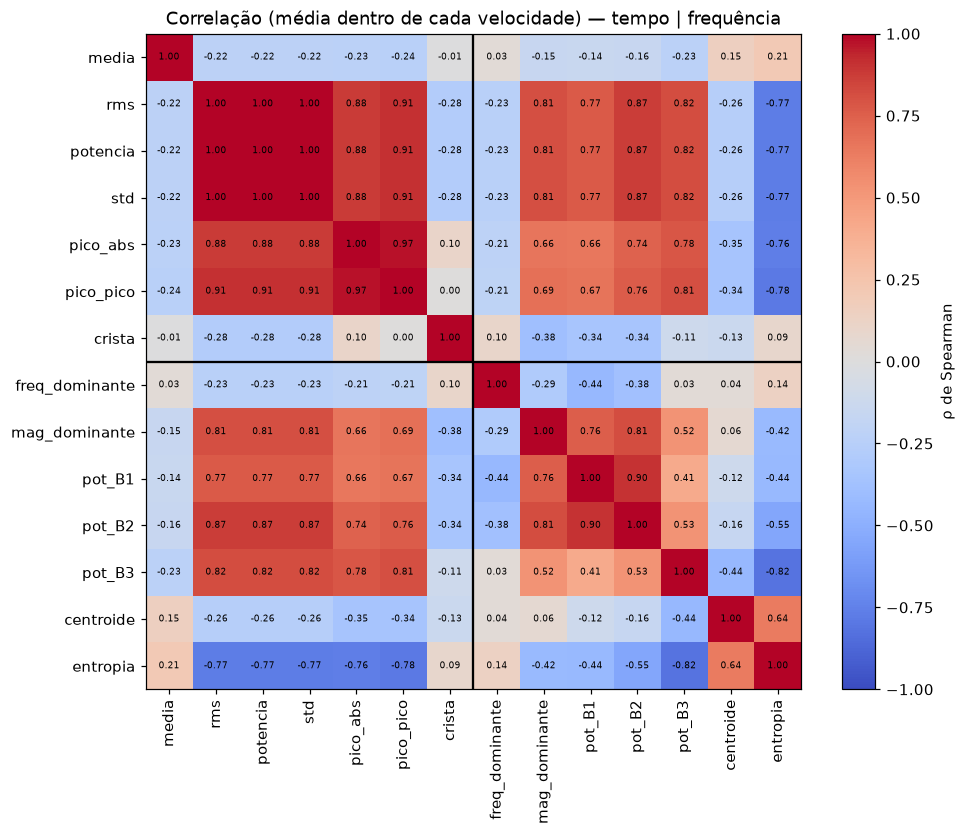

Pares redundantes (|ρ| ≥ 0,85):


,característica 1,característica 2,ρ
0,rms,potencia,1.00
1,rms,std,1.00
2,rms,pico_abs,0.88
3,rms,pico_pico,0.91
4,rms,pot_B2,0.87
5,potencia,std,1.00
6,potencia,pico_abs,0.88
7,potencia,pico_pico,0.91
8,potencia,pot_B2,0.87
9,std,pico_abs,0.88


In [16]:
cols = FT + FF
corr = sum(g[cols].corr(method="spearman") for _, g in df.groupby("speed")) / df.speed.nunique()

fig, a = plt.subplots(figsize=(9, 7.5))
im = a.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
a.set_xticks(range(len(cols)))
a.set_xticklabels(cols, rotation=90)
a.set_yticks(range(len(cols)))
a.set_yticklabels(cols)
a.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        a.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
a.axhline(len(FT) - 0.5, color="k", lw=1.5)
a.axvline(len(FT) - 0.5, color="k", lw=1.5)
fig.colorbar(im, label="ρ de Spearman")
a.set_title("Correlação (média dentro de cada velocidade) — tempo | frequência")
fig.tight_layout()
plt.show()

pares = [(c1, c2, corr.loc[c1, c2]) for k, c1 in enumerate(cols) for c2 in cols[k + 1:]
         if abs(corr.loc[c1, c2]) >= 0.85]
print("Pares redundantes (|ρ| ≥ 0,85):")
display(pd.DataFrame(pares, columns=["característica 1", "característica 2", "ρ"]).round(2))

### Discussão

✏️ *Confira os números com as tabelas acima e ajuste a lista final.*

**Achado 1: o tempo mostra *quanto*, a frequência mostra *onde*.** Em SP1, o RMS separa as condições (AUC ≈ 0,74), mas a vantagem cai em SP2 e SP3 (≈ 0,61 e 0,57), e o sentido muda (saudável com mais energia em SP1, menos em SP2/SP3). O espectro do mesmo par (3.3.3) explica a diferença de SP1: no saudável a energia está concentrada numa fundamental e nos harmônicos, e no defeituoso está espalhada. Isso aparece na magnitude do pico dominante (AUC ≈ 0,79 em SP1) e na instabilidade da frequência dominante do defeituoso, informação que o gráfico temporal não dá.

**Achado 2: a energia é a mesma nos dois domínios.** RMS, potência e desvio padrão são, na prática, a mesma medida ($\rho \approx 1$, já que $\mu \approx 0$). Pico absoluto e pico a pico acompanham o desvio padrão ($\rho \approx 0{,}9$). E, por Parseval, as potências de banda somam exatamente $\sigma^2$, então ao menos uma banda fica muito correlacionada com o desvio padrão (na execução anterior, a de 50–300 Hz, $\rho \approx 0{,}87$). O que o domínio da frequência acrescenta de novo é a **forma** do espectro (entropia, centroide, pico dominante), não a energia.

**Quais separam melhor.**

- **Tempo:** o fator de crista é a única medida temporal com o mesmo sentido nas três velocidades (defeituoso mais impulsivo), com AUC alta em SP1 e SP3. As medidas de energia separam bem só em SP1.
- **Frequência:** a entropia espectral tem AUC ≥ 0,7 nas três velocidades. A magnitude do pico dominante e as potências de banda vêm em seguida. A frequência dominante é a mais fraca (AUC 0,51–0,64), porque salta entre harmônicos.

**Conjunto proposto para a classificação** (um representante por grupo redundante):

- Tempo: `std` (representa RMS, potência, pico absoluto e pico a pico) e `crista`. A `media` fica fora: é um *offset* de ≈ −0,001 g sem relação com a hélice.
- Frequência: `entropia`, `centroide`, `mag_dominante` e as bandas que **não** estiverem na lista de pares redundantes com `std`. `freq_dominante` fica como opcional, pela instabilidade.

## 3.6 Investigação adicional

**Pergunta:** *como a velocidade de rotação (SP1 → SP3) modifica os picos espectrais? Os picos formam uma série harmônica de uma mesma fundamental?*

**Método.** Para cada velocidade, usamos os registros equivalentes ao par da 3.2 (canal C1, R1): saudável `F0_SV0_SPx_C1_R1` e defeituoso `F2_SV2_SPx_C1`. Calculamos o espectro médio das janelas, tomamos como fundamental $f_0$ o maior pico entre 20 e 300 Hz e listamos os 5 picos mais proeminentes até 1 kHz com a razão $f/f_0$. Razões próximas de inteiros indicam harmônicos.

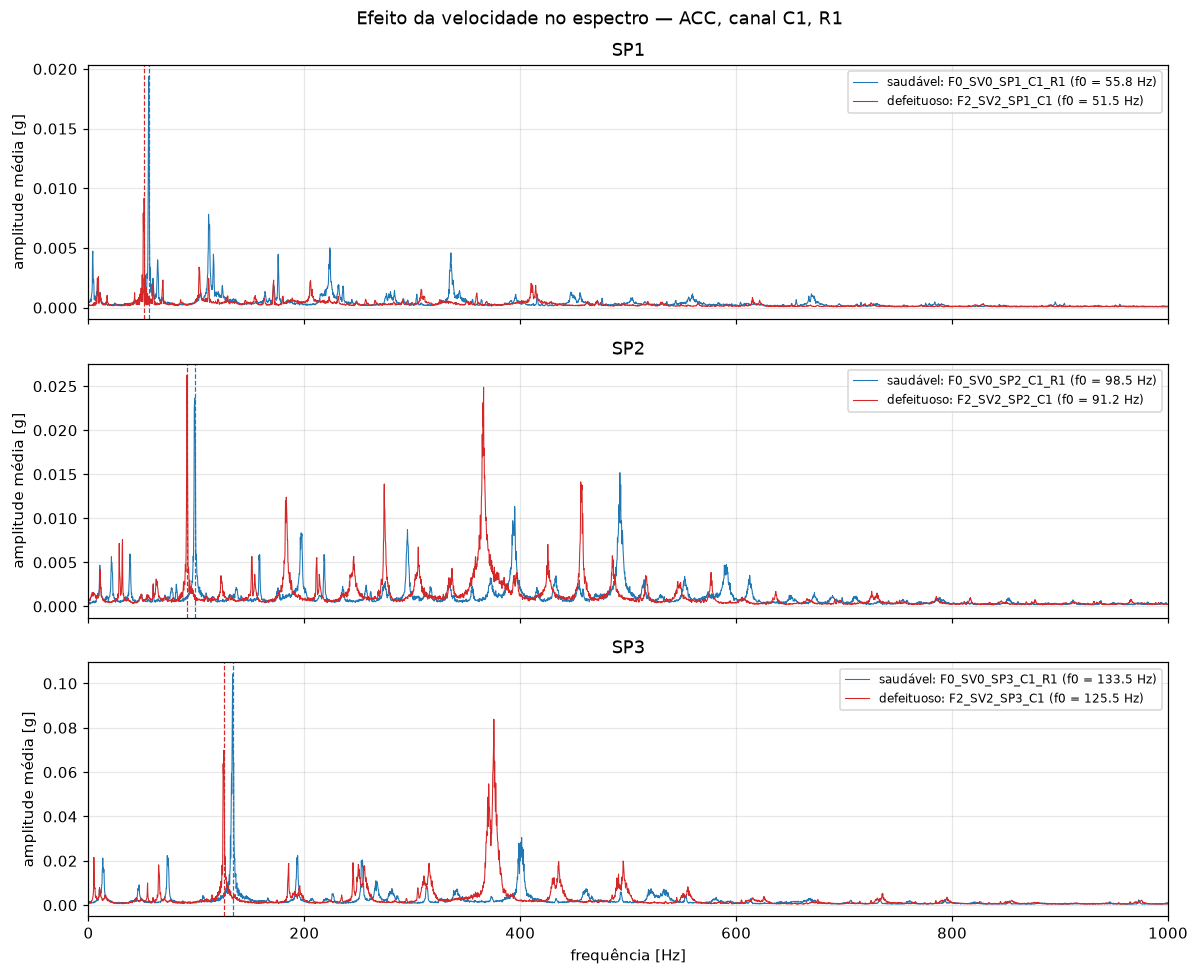

,speed,condicao,f0_hz,picos_hz,razao_f_f0
0,SP1,saudável,55.75,"4, 56, 111, 224, 336","0.07, 1.00, 2.00, 4.01, 6.02"
1,SP1,defeituoso,51.50,"9, 50, 52, 53, 102","0.18, 0.97, 1.00, 1.02, 1.99"
2,SP2,saudável,98.50,"98, 197, 296, 395, 492","1.00, 2.00, 3.00, 4.01, 5.00"
3,SP2,defeituoso,91.25,"91, 183, 274, 366, 456","1.00, 2.01, 3.00, 4.01, 5.00"
4,SP3,saudável,133.50,"13, 73, 134, 194, 401","0.10, 0.55, 1.00, 1.45, 3.01"
5,SP3,defeituoso,125.50,"5, 126, 371, 376, 495","0.04, 1.00, 2.95, 2.99, 3.95"


Razão da fundamental em relação a SP1 (saudável): {'SP1': 1.0, 'SP2': 1.77, 'SP3': 2.39}


In [17]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
linhas = []
for a, sp in zip(ax, (1, 2, 3)):
    for cond, rid in {"saudável": f"F0_SV0_SP{sp}_C1_R1", "defeituoso": f"F2_SV2_SP{sp}_C1"}.items():
        m = (jan.record_id == rid).to_numpy()
        if not m.any():
            continue
        f, A, _ = fft_janelas(W[m], FS)
        Am = A.mean(axis=0)
        faixa = (f >= 20) & (f <= 300)
        f0 = f[faixa][Am[faixa].argmax()]
        picos = sorted(fp for fp, _ in top_picos(f, Am, k=5))
        a.plot(f[1:], Am[1:], lw=0.7, color=CORES[cond], label=f"{cond}: {rid} (f0 = {f0:.1f} Hz)")
        a.axvline(f0, color=CORES[cond], ls="--", lw=0.8)
        linhas.append(dict(speed=f"SP{sp}", condicao=cond, f0_hz=round(f0, 2),
                           picos_hz=", ".join(f"{p:.0f}" for p in picos),
                           razao_f_f0=", ".join(f"{p / f0:.2f}" for p in picos)))
    a.set_title(f"SP{sp}")
    a.set_ylabel(f"amplitude média [{UNIDADE}]")
    a.legend(loc="upper right", fontsize=8)
ax[-1].set_xlim(0, 1000)
ax[-1].set_xlabel("frequência [Hz]")
fig.suptitle("Efeito da velocidade no espectro — ACC, canal C1, R1")
fig.tight_layout()
plt.show()

res36 = pd.DataFrame(linhas)
display(res36)
f0s = res36[res36.condicao == "saudável"].set_index("speed").f0_hz
print("Razão da fundamental em relação a SP1 (saudável):", (f0s / f0s.iloc[0]).round(2).to_dict())

**Conclusão.** ✏️ *Confira com a tabela acima.* A fundamental sobe com a velocidade (≈ 56 → 98 → 134 Hz no saudável, ou seja, 1,75× e 2,4× a de SP1), e os demais picos se deslocam junto: em SP1 aparecem 56, 111, 224 e 335 Hz (razões ≈ 1, 2, 4, 6); em SP2, 98, 395 e 492 Hz (≈ 1, 4, 5); em SP3, 134 e 401 Hz (≈ 1, 3). Os picos são, portanto, uma **série harmônica de uma fundamental que acompanha a velocidade**, compatível com uma relação com a rotação do motor/hélice, o que não podemos afirmar sem medir a rotação. Saudável e defeituoso têm fundamentais próximas na mesma velocidade; o que muda é a **amplitude relativa** dos harmônicos.

**Consequências para o projeto:** (i) como os harmônicos mudam de lugar com a velocidade, uma banda fixa (ex.: 50–300 Hz) contém harmônicos diferentes em cada SP, o que reforça comparar e classificar **dentro da mesma velocidade** ou incluir a velocidade como variável; (ii) características normalizadas por $f_0$ (ex.: energia no 1º, 2º... harmônico) seriam uma extensão natural para a classificação. **Limitação:** um registro por condição e velocidade; para generalizar, repita trocando o canal (C2, C3) ou o tipo de defeito no código acima.